**Reconstruction**

In [1]:
import warnings
warnings.filterwarnings('ignore')
import random
import sys
# base_path = "/content/drive/MyDrive/CVB"
# sys.path.append("/content/drive/MyDrive/CVB")


from src.data import load_victim_data
from src.utils import build_config, update_config, get_device, set_seeds, show_multiple
from src.models.modelzoo import get_model
from src.attacks import get_attack

In [19]:
#DATASET = 'MNIST'
DATASET = 'CIFAR10'
#DATASET = 'MedMNISTBlood'
#DATASET = 'MedMNISTDerma'
#DATASET = 'MedMNISTPneumonia'
#DATASET = 'MedMNISTRetina'

MODEL = 'CNN'
#MODEL = 'ViT'
#MODEL = 'ResNet18'


# ATTACK = 'iDLG'
#ATTACK = 'DIA'
#ATTACK = 'CPL'
# ATTACK = "IG"
ATTACK = "VBIA"

VICTIM_BATCHSIZE = 1
NUM_BATCHES = 3
NUM_SAMPLES = VICTIM_BATCHSIZE * NUM_BATCHES # should not exceed victim dataset size of 128

SEED = 42
DEBUG_RUN = True
DEVICE = get_device()

GPU : NVIDIA GeForce RTX 3060


In [15]:
config = build_config('configs/main_config.yaml')
training_config = build_config('./configs/fedavg.yaml')
config = update_config(config, training_config)
attack_config = build_config(f'./configs/attacks/{ATTACK}.yaml')
config = update_config(config, attack_config)
data_config = build_config(f'./configs/data/{DATASET}.yaml')
config = update_config(config, data_config)

config.seed = SEED
config.debug = DEBUG_RUN
config.attack.num_samples = NUM_SAMPLES
config.attack.num_batches = NUM_BATCHES
config.attack.victim_batchsize = VICTIM_BATCHSIZE
config.device = DEVICE
config.experiment_name = f'{DATASET}_{MODEL}_{ATTACK}_seed{SEED}'


Loaded victim data from ./data/victim_datasets/CIFAR10_128.tdump!
Loaded victim dataset CIFAR10 with batchsize 1. Data samples are of shape torch.Size([3, 32, 32]).
Seed was set to 42


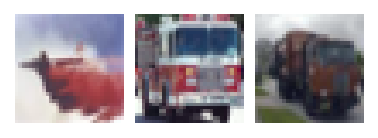

In [11]:
victim_inputs, victim_targets, data_shape = load_victim_data(f'./data/victim_datasets/{DATASET}_128.tdump', VICTIM_BATCHSIZE)
print(f'Loaded victim dataset {DATASET} with batchsize {VICTIM_BATCHSIZE}. Data samples are of shape {data_shape}.')
#show_multiple(victim_inputs, 16, 8, img_scale=DATASET) # SHOW WHOLE VICTIM DATASET


set_seeds(SEED)
assert NUM_SAMPLES <= 128
selection = random.sample(range(len(victim_targets)), NUM_BATCHES)

selected_vicitm_inputs = [victim_inputs[i] for i in selection]
selected_vicitm_targets = [victim_targets[i] for i in selection]

original_imgs = []
for img_batch in selected_vicitm_inputs:
    original_imgs.extend(img_batch.split(1))
show_multiple(original_imgs, NUM_SAMPLES, 1, img_scale=DATASET, figsize=(NUM_SAMPLES, 1))

# BASELINE MODEL

In [20]:
model_config = build_config(f'./configs/models/{MODEL}.yaml')
config = update_config(config, model_config)

model = get_model(config.model.name, config)
model = model.to(config.device)
model

Loaded model with CNN architecture, input shape [3, 32, 32], 10 classes.
Setting the models checkpoint path to ./checkpoints/CIFAR10_CNN_IG_seed42.ckpt


CNN(
  (conv_layers): ModuleList(
    (0): CNNBlock(
      (conv): Conv2d(3, 16, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
    (1): CNNBlock(
      (conv): Conv2d(16, 32, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
    (2): CNNBlock(
      (conv): Conv2d(32, 64, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
  )
  (mlp_layers): ModuleList(
    (0): MLPBlock(
      (linear): Linear(in_features=64, out_features=10, bias=True)
      (regularization_layers): ModuleList()
    )
  )
)

In [21]:
if DEBUG_RUN:
    config.attack.max_iterations = 1200
attacker = get_attack(config.attack.name, config.data.dataset, model, selected_vicitm_inputs, selected_vicitm_targets, config)
print('________________________________________________________')
reconstructions, results = attacker.attack()

Victim batchsize: 1
Max iterations: 1200
________________________________________________________
Attacking victim batch 0!
Using Adam optimizer with learning rate 1
Reconstruction was stopped after 1200 iterations for batch 0 trial 0
Execution of attack_batch took 0.13 minutes.
The reconstruction reached a mean MSE score of 0.018635.
The reconstruction reached a mean PSNR score of 26.83921.
The reconstruction reached a mean SSIM score of 0.71331.
The reconstruction reached a mean LPIPS score of 0.17988.
The reconstruction reached a best reconstruction loss of 0.0306478 after 1032 iterations.
Attacking victim batch 1!
Using Adam optimizer with learning rate 1
Reconstruction was stopped after 1200 iterations for batch 1 trial 0
Execution of attack_batch took 0.13 minutes.
The reconstruction reached a mean MSE score of 0.031543.
The reconstruction reached a mean PSNR score of 24.55341.
The reconstruction reached a mean SSIM score of 0.59386.
The reconstruction reached a mean LPIPS score 

________________________________________________________
Originals:


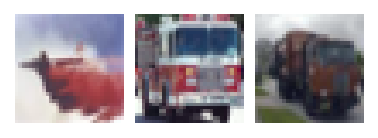

Reconstructions:


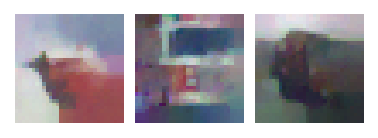

In [18]:
reconstructed_images = []
for b in range(NUM_BATCHES):
    reconstructed_images.extend(reconstructions[b]['Reconstructions'].split(1))
print('________________________________________________________')
print('Originals:')
show_multiple(original_imgs, NUM_SAMPLES, 1, img_scale = DATASET, figsize=(NUM_SAMPLES, 1))
print('Reconstructions:')
show_multiple(reconstructed_images, NUM_SAMPLES, 1, img_scale = DATASET, figsize=(NUM_SAMPLES, 1))

### Get the model (CVB protected) with Ignore Attack

In [5]:
model_config = build_config(f'./configs/models/{MODEL}CVB.yaml')
config = update_config(config, model_config)

model = get_model(config.model.name, config)
model = model.to(config.device)
model

Loaded model with VBCNN architecture, input shape [3, 32, 32], 10 classes.
Setting the models checkpoint path to ./checkpoints/CIFAR10_CNN_VBIA_seed42.ckpt


VBCNN(
  (conv_layers): ModuleList(
    (0): CNNBlock(
      (conv): Conv2d(3, 16, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
    (1): CNNBlock(
      (conv): Conv2d(16, 32, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
    (2): CNNBlock(
      (conv): Conv2d(32, 64, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
  )
  (mlp_layers): ModuleList(
    (0): MLPBlock(
      (linear): Linear(in_features=64, out_features=10, bias=True)
      (regularization_layers): ModuleList()
    )
  )
  (VB_list): ModuleList(
    (0): FullyConvolutionalVariationalBottleneck(
      (encoder): ConvolutionalVariationalEncoder(
        (mu_encoder): Conv2d(16, 8, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
        (std_encoder): Conv2d(16, 8, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
      )
      (decoder): ConvolutionalVariationalDeco

In [6]:
if DEBUG_RUN:
    config.attack.max_iterations = 1200
attacker = get_attack(config.attack.name, config.data.dataset, model, selected_vicitm_inputs, selected_vicitm_targets, config)
print('________________________________________________________')
reconstructions, results = attacker.attack()

Victim batchsize: 1
Max iterations: 1200
________________________________________________________
VB LATENT SHAPE: torch.Size([1, 8, 14, 14])
Attacking victim batch 0!
Using Adam optimizer with learning rate 0.01
Reconstruction was stopped after 1200 iterations for batch 0 trial 0
Execution of attack_batch took 0.22 minutes.
The reconstruction reached a mean MSE score of 0.080914.
The reconstruction reached a mean PSNR score of 20.46218.
The reconstruction reached a mean SSIM score of 0.17753.
The reconstruction reached a mean LPIPS score of 0.59754.
The reconstruction reached a best reconstruction loss of 0.5646510 after 1193 iterations.
Attacking victim batch 1!
Using Adam optimizer with learning rate 0.01
Reconstruction was stopped after 1200 iterations for batch 1 trial 0
Execution of attack_batch took 0.17 minutes.
The reconstruction reached a mean MSE score of 0.061833.
The reconstruction reached a mean PSNR score of 21.63024.
The reconstruction reached a mean SSIM score of 0.120

________________________________________________________
Originals:


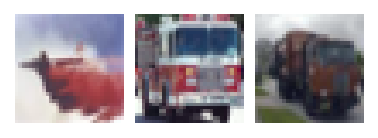

Reconstructions:


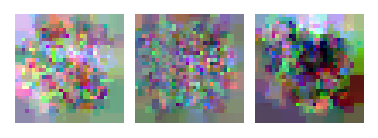

In [7]:
reconstructed_images = []
for b in range(NUM_BATCHES):
    reconstructed_images.extend(reconstructions[b]['Reconstructions'].split(1))
print('________________________________________________________')
print('Originals:')
show_multiple(original_imgs, NUM_SAMPLES, 1, img_scale = DATASET, figsize=(NUM_SAMPLES, 1))
print('Reconstructions:')
show_multiple(reconstructed_images, NUM_SAMPLES, 1, img_scale = DATASET, figsize=(NUM_SAMPLES, 1))

## Baseline attack (without our "Ignore" mechanism)

In [38]:
model_config = build_config(f'./configs/models/{MODEL}CVB.yaml')
config = update_config(config, model_config)

model = get_model(config.model.name, config)
model = model.to(config.device)
model

Loaded model with VBCNN architecture, input shape [3, 32, 32], 10 classes.
Setting the models checkpoint path to ./checkpoints/CIFAR10_CNN_VBIA_seed42.ckpt


VBCNN(
  (conv_layers): ModuleList(
    (0): CNNBlock(
      (conv): Conv2d(3, 16, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
    (1): CNNBlock(
      (conv): Conv2d(16, 32, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
    (2): CNNBlock(
      (conv): Conv2d(32, 64, kernel_size=(5, 5), stride=(2, 2), padding=valid)
      (activation_function): ReLU()
    )
  )
  (mlp_layers): ModuleList(
    (0): MLPBlock(
      (linear): Linear(in_features=64, out_features=10, bias=True)
      (regularization_layers): ModuleList()
    )
  )
  (VB_list): ModuleList(
    (0): FullyConvolutionalVariationalBottleneck(
      (encoder): ConvolutionalVariationalEncoder(
        (mu_encoder): Conv2d(16, 8, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
        (std_encoder): Conv2d(16, 8, kernel_size=(5, 5), stride=(1, 1), padding=same, bias=False)
      )
      (decoder): ConvolutionalVariationalDeco

In [39]:
if DEBUG_RUN:
    config.attack.max_iterations = 1200
attacker = get_attack(config.attack.name, config.data.dataset, model, selected_vicitm_inputs, selected_vicitm_targets, config)
print('________________________________________________________')
reconstructions, results = attacker.attack()

Victim batchsize: 1
Max iterations: 1200
________________________________________________________
VB LATENT SHAPE: torch.Size([1, 8, 14, 14])
Attacking victim batch 0!
Using Adam optimizer with learning rate 0.01
Reconstruction was stopped after 1200 iterations for batch 0 trial 0
Execution of attack_batch took 0.17 minutes.
The reconstruction reached a mean MSE score of 0.069088.
The reconstruction reached a mean PSNR score of 21.14837.
The reconstruction reached a mean SSIM score of 0.20267.
The reconstruction reached a mean LPIPS score of 0.56325.
The reconstruction reached a best reconstruction loss of 0.5196113 after 1115 iterations.
Attacking victim batch 1!
Using Adam optimizer with learning rate 0.01
Reconstruction was stopped after 1200 iterations for batch 1 trial 0
Execution of attack_batch took 0.17 minutes.
The reconstruction reached a mean MSE score of 0.056429.
The reconstruction reached a mean PSNR score of 22.02741.
The reconstruction reached a mean SSIM score of 0.196

________________________________________________________
Originals:


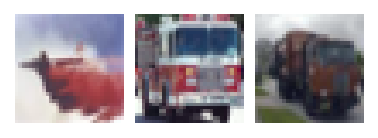

Reconstructions:


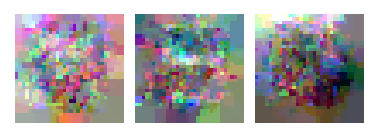

In [40]:
reconstructed_images = []
for b in range(NUM_BATCHES):
    reconstructed_images.extend(reconstructions[b]['Reconstructions'].split(1))
print('________________________________________________________')
print('Originals:')
show_multiple(original_imgs, NUM_SAMPLES, 1, img_scale = DATASET, figsize=(NUM_SAMPLES, 1))
print('Reconstructions:')
show_multiple(reconstructed_images, NUM_SAMPLES, 1, img_scale = DATASET, figsize=(NUM_SAMPLES, 1))